## Аналитическое решение

Уходя из детского сада, каждый из $n$ случайно берет один левый и один правый ботинок. Найти вероятность того, что каждый их них возьмет не свой левый и не свой правый ботинок.

---

1) Посчитаем вероятность того, что каждый из детей возьмет не свой левый ботинок (событие $B$). Для правого все симметрично (событие $C$), а выбор правых и левых ботинков независим, поэтому искомая $P(A B) = P(A) P(B) = P(A)^{2}$ 

2) Процесс того, что $n$ детей выбирают себе ботинок, можно описать перестановкой $p$, где $p_{i}$ -- номер ребенка, чей ботинок взял ребенок с номером $i$. То есть мы ищем вероятность $P_{perm}(n)$ того, что для перестановки $p$ чисел от $1$ до $n$ верно:

$\forall i \in [1:n] : p_{i} \neq i$.

3) Найдем $P_{perm}(n)$ с помощью формулы включения-исключения:

Пусть $P(B_{i_{1}} ... B_{i_{k}})$ -- вероятность того, что

$p_{i_{1}} = i_{1}$, ... $p_{i_{k}} = i_{k}$

Найдем эту вероятность комбинаторно: фиксируем $k$ элементов, по остальным ищем все перестановки:

$P(B_{i_{1}} ... B_{i_{k}}) = \frac{(n - k)!}{n!}$

4) Найдем сначала $1 - P_{perm}(n)$

$1 - P_{perm}(n) = P(B_{1} | ... | B_{k})$ -- вероятность того, что хоть на одной позиции совпадет

$P(B_{1} | ... | B_{k}) = \sum_{k=1}^{n} (-1)^{k - 1} \sum_{разные i_{1}, ... i_{k} \in [1:n]} P(B_{i_{1}} ... B_{i_{k}}) = \sum_{k=1}^{n}(-1)^{k - 1} C_{n}^{k} \frac{(n - k)!}{n!} = \sum_{k=1}^{n}(-1)^{k - 1} \frac{n!(n-k)!}{k!(n-k)!n!} = \sum_{k=1}^{n}(-1)^{k - 1} \frac{1}{k!} = 1 - (\sum_{k=0}^{n} \frac{(-1)^{k}}{k!})$ 

5) $P_{perm}(n) = 1 - P(B_{1} | ... | B_{k}) = \sum_{k=0}^{n} \frac{(-1)^{k}}{k!}$

6) Это только для одного ботинка. Для двух $P_{target}(n) = P_{perm}(n)^{2}$

Заметим, что при $n \to +\infty$ имеем $P_{perm}(n) \to e^{-1} = \frac{1}{e}$, и $P_{target}(n) \to \frac{1}{e^2}$

In [ ]:
import math
import random

# Возвращает аналитический ответ
def calculate_analytical(n):
    result = 0

    for k in range(n + 1):
        if k % 2 == 0:
            # even
            result += 1 / math.factorial(k)
        else:
            # odd
            result -= 1 / math.factorial(k)

    return result ** 2

# Проводит один эксперимент, если все дети надели чужие
# сапоги, возвращается True
def kids_one_iteration(n) -> bool:
    left_boots = [i for i in range(1, n + 1)]
    right_boots = [i for i in range(1, n + 1)]

    for i in range(1, n + 1):
        left_boot_index = random.randint(0, len(left_boots) - 1)
        right_boot_index = random.randint(0, len(right_boots) - 1)

        if left_boots[left_boot_index] == i or right_boots[right_boot_index] == i:
            return False

        left_boots.pop(left_boot_index)
        right_boots.pop(right_boot_index)

    return True

# Проводит n_iterations тесты и возвращает эмпирическую вероятность:
# (количество успешных тестов)/n_iterations
def get_kids_probability(n_kids, n_iterations):
    success = 0

    for i in range(n_iterations):
        if kids_one_iteration(n_kids):
            success += 1

    return success / n_iterations

In [65]:
!pip3 install matplotlib numpy

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def graph_convergence(n_kids, max_iterations=50_000, n_points=60):
    iteration_counts = np.linspace(100, max_iterations, n_points).astype(int)
    probabilities = [get_kids_probability(n_kids, it) for it in iteration_counts]

    plt.figure(figsize=(10, 6))
    plt.plot(iteration_counts, probabilities, marker='o', label='get_kids_probability')
    plt.axhline(calculate_analytical(n_kids), color='red', linestyle='--', label=f'calculate_analytical({n_kids})')
    plt.xlabel('Количество итераций')
    plt.ylabel('Вероятность')
    plt.legend()
    plt.grid(True)
    plt.show()



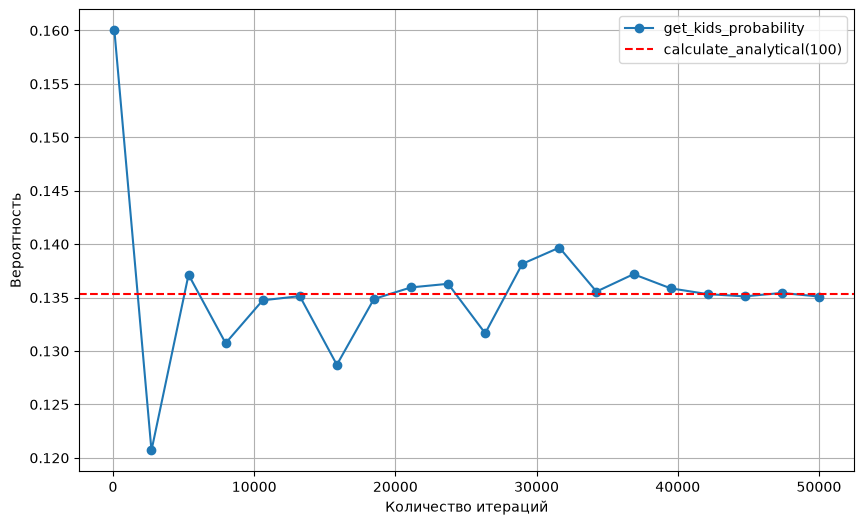

In [73]:
graph_convergence(100, max_iterations=50_000, n_points=20)